In [ ]:
!pip install --upgrade pip
!pip install --upgrade tensorflow -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 29.1 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 158.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 131.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [tensorflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-text 2.18.1 requires tensorflow<2.19,>=2.18.0, but you have tensorflow 2.19.0 which is incompatible.
tensorflow-decision-forests 1.11.0 requires tensorflow==2.18.0, but you have tensorflow 2.19.0 which is incompatible.
tf-keras 2.18.0 requires tensorflow<2.19,>=2.18, but you have tensorflow 2.19

In [ ]:
!apt-get install wget -q

Reading package lists...
Building dependency tree...
Reading state information...
wget is already the newest version (1.21.2-2ubuntu1.1).
0 upgraded, 0 newly installed, 0 to remove and 34 not upgraded.


In [ ]:
!pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.0/68.0 kB 3.7 MB/s eta 0:00:00


In [ ]:
import kagglehub
import os

# Set download path to current directory
current_path = os.getcwd()

# Download latest version to current path
path = kagglehub.dataset_download("sonu26072001/mura-final", path=current_path)

print("Path to dataset files:", path)


In [ ]:
import os
import sys
from tempfile import NamedTemporaryFile
from urllib.request import urlopen
from urllib.parse import unquote, urlparse
from urllib.error import HTTPError
from zipfile import ZipFile
import tarfile
import shutil

In [ ]:
import shutil

# Source path in your Google Drive
source_path = "/Users/zakiraltaf/.cache/kagglehub/datasets/sonu26072001/mura-final/versions/1"

# Destination path in Colab
destination_path = "/content/MURA"

# Copy the files (and directories if any)
shutil.copytree(source_path, destination_path, dirs_exist_ok=True)

print("Files copied successfully!")

Files copied successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import *
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import cv2
import glob
import copy
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, cohen_kappa_score
)

# Check TensorFlow version and GPU availability
print("TensorFlow version:", tf.__version__)
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))






TensorFlow version: 2.16.2
Num GPUs Available: 0


In [ ]:
# Load data paths - UPDATED DATASET PATHS
elbow_negative = glob.glob('finaldata/valid_final/XR_ELBOW/negative/*.png')
elbow_positive = glob.glob('finaldata/valid_final/XR_ELBOW/positive/*.png')
elbow_negative_t = glob.glob('finaldata/train_final/XR_ELBOW/negative/*.png')
elbow_positive_t = glob.glob('finaldata/train_final/XR_ELBOW/positive/*.png')

# Function to load and preprocess images
def load_data(paths, label, limit=None):
    data = []
    labels = []
    count = 0

    for path in paths:
        if limit is not None and count >= limit:
            break

        img = cv2.imread(path, 1)
        img = cv2.resize(img, (224, 224))
        data.append(img)
        labels.append(label)
        count += 1

    return data, labels

# Load all images
print("Loading images...")
data = []
labels = []

# Load negative/fractured images (class - 0)
fractured_data, fractured_labels = load_data(elbow_negative, 0, limit=1500)
data.extend(fractured_data)
labels.extend(fractured_labels)

# Load positive/non-fractured images (class - 1)
not_fractured_data, not_fractured_labels = load_data(elbow_positive, 1)
data.extend(not_fractured_data)
labels.extend(not_fractured_labels)

# Load validation negative/fractured images
val_fractured_data, val_fractured_labels = load_data(elbow_negative_t, 0)
data.extend(val_fractured_data)
labels.extend(val_fractured_labels)

# Load validation positive/non-fractured images
val_not_fractured_data, val_not_fractured_labels = load_data(elbow_positive_t, 1)
data.extend(val_not_fractured_data)
labels.extend(val_not_fractured_labels)

# Convert to numpy arrays
data = np.array(data)
labels = np.array(labels)

print(f"Dataset loaded: {data.shape[0]} images")
print(f"Class distribution: {np.sum(labels == 0)} negative/fractured, {np.sum(labels == 1)} positive/non-fractured")

# Create the model architecture
def create_model():
    # Load the base model
    base_model = EfficientNetB3(weights='imagenet', input_shape=(224, 224, 3), include_top=False)
    base_model.trainable = False  # Freeze the layers of the base model

    # Input layer
    inputs = Input(shape=(224, 224, 3))

    # Pass through the base model
    x = base_model(inputs, training=False)
    x = GaussianNoise(0.25)(x)
    x = GlobalAveragePooling2D()(x)

    # Dense layers
    x = Dense(512, activation='relu')(x)
    x = BatchNormalization()(x)
    x = GaussianNoise(0.25)(x)
    x = Dropout(0.25)(x)

    # Attention layer (Self-attention mechanism)
    def self_attention(x):
        attention = Dense(512, activation='tanh')(x)
        attention = tf.keras.layers.Softmax()(attention)
        attention = Multiply()([x, attention])
        return attention

    # Apply self-attention mechanism
    attention_output = self_attention(x)

    # Flatten the output for dense layers
    x = Flatten()(attention_output)

    # Further layers
    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.15)(x)

    # Output layer (for binary classification)
    outputs = Dense(1, activation='sigmoid')(x)

    # Define the model
    model = Model(inputs, outputs)

    # Compile the model
    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy', 'Precision', 'Recall', 'AUC']
    )

    return model

# Data augmentation setup
def create_data_generator():
    return ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest'
    )

# Function to visualize augmented images
def visualize_augmentation(images, labels, datagen, n_samples=5):
    # Select some sample images
    sample_indices = np.random.choice(range(len(images)), n_samples, replace=False)
    sample_images = images[sample_indices]
    sample_labels = labels[sample_indices]

    plt.figure(figsize=(20, 4*n_samples))

    for i in range(n_samples):
        # Original image
        plt.subplot(n_samples, 5, i*5 + 1)
        plt.imshow(sample_images[i].astype('uint8'))
        plt.title(f"Original: {'Positive' if sample_labels[i] == 1 else 'Negative'}")
        plt.axis('off')

        # Generate 4 augmented versions
        img = sample_images[i].reshape((1,) + sample_images[i].shape)
        aug_iter = datagen.flow(img, batch_size=1)

        for j in range(4):
            plt.subplot(n_samples, 5, i*5 + j + 2)
            # Use next() function instead of .next() method
            aug_img = next(aug_iter)[0].astype('uint8')
            plt.imshow(aug_img)
            plt.title(f"Augmented {j+1}")
            plt.axis('off')

    plt.tight_layout()
    plt.show()

# Plot training history
def plot_training_history(history, title_prefix=""):
    # Make a safe copy so we don't modify the original in place
    clean_hist_dict = copy.deepcopy(history.history)

    # Loop over each key in the dictionary
    for key, values in clean_hist_dict.items():
        # Filter out any elements equal to 0.0
        clean_hist_dict[key] = [v for v in values if v != 0.0]

    # Create a single figure with subplots
    plt.figure(figsize=(15, 10))

    # Accuracy
    plt.subplot(2, 2, 1)
    plt.title(f'{title_prefix} Accuracy')
    plt.plot(clean_hist_dict['accuracy'], label='training accuracy')
    plt.plot(clean_hist_dict['val_accuracy'], label='validation accuracy')
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    # Loss
    plt.subplot(2, 2, 2)
    plt.title(f'{title_prefix} Loss')
    plt.plot(clean_hist_dict['loss'], label='training loss')
    plt.plot(clean_hist_dict['val_loss'], label='validation loss')
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    # Precision and Recall
    plt.subplot(2, 2, 3)
    plt.title(f'{title_prefix} Precision & Recall')
    plt.plot(clean_hist_dict['Precision'], label='Train Precision')
    plt.plot(clean_hist_dict['val_Precision'], label='Val Precision')
    plt.plot(clean_hist_dict['Recall'], label='Train Recall', linestyle='--')
    plt.plot(clean_hist_dict['val_Recall'], label='Val Recall', linestyle='--')
    plt.xlabel("Epochs")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    # AUC
    plt.subplot(2, 2, 4)
    plt.title(f'{title_prefix} AUC')
    plt.plot(clean_hist_dict['AUC'], label='Train')
    plt.plot(clean_hist_dict['val_AUC'], label='Validation')
    plt.xlabel("Epochs")
    plt.ylabel("AUC")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

    return clean_hist_dict

# Function to evaluate model and display metrics
def evaluate_and_visualize(model, x_test, y_test, title_prefix=""):
    # Get predictions
    y_pred_proba = model.predict(x_test)
    y_pred_binary = (y_pred_proba > 0.5).astype(int)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred_binary)
    precision = precision_score(y_test, y_pred_binary)
    recall = recall_score(y_test, y_pred_binary)
    f1 = f1_score(y_test, y_pred_binary)
    kappa = cohen_kappa_score(y_test, y_pred_binary)

    # Print metrics
    print(f'{title_prefix} Model Evaluation:')
    print(f'Accuracy: {accuracy:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall: {recall:.4f}')
    print(f'F1 Score: {f1:.4f}')
    print(f'Kappa Score: {kappa:.4f}')

    # Display classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred_binary))

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(16, 6))

    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{title_prefix} ROC Curve')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle='--', alpha=0.7)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_binary)

    plt.subplot(1, 2, 2)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'])
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title(f'{title_prefix} Confusion Matrix')

    plt.tight_layout()
    plt.show()

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'kappa': kappa,
        'roc_auc': roc_auc
    }

# Function to train with different data splits
def train_with_split_ratio(train_ratio, epochs_list=[10, 20], use_augmentation=True):
    results = []

    # Create data generator for augmentation
    if use_augmentation:
        datagen = create_data_generator()
        # Visualize some augmented samples
        visualize_augmentation(data, labels, datagen, n_samples=3)
    else:
        datagen = None

    for epochs in epochs_list:
        print(f"\n{'='*80}")
        print(f" Training with {train_ratio*100:.0f}% train - {(1-train_ratio)*100:.0f}% test split, {epochs} epochs, augmentation: {use_augmentation}")
        print(f"{'='*80}")

        # Split data
        x_train, x_test, y_train, y_test = train_test_split(
            data, labels, train_size=train_ratio,
            random_state=42, stratify=labels
        )

        print(f"Training samples: {len(x_train)}, Test samples: {len(x_test)}")

        # Create and compile model
        model = create_model()

        # Setup callbacks
        callbacks = [
            ReduceLROnPlateau(monitor="val_loss", factor=0.1, patience=2),
            ModelCheckpoint(
                f'/content/model_{int(train_ratio*100)}_{epochs}{"_aug" if use_augmentation else ""}.keras',
                monitor='val_accuracy',
                verbose=1,
                save_best_only=True,
                mode='max'
            ),
            EarlyStopping(
                monitor='val_loss',
                patience=5,
                restore_best_weights=True
            )
        ]

        # Train the model
        if use_augmentation:
            # Fit with data augmentation
            train_generator = datagen.flow(x_train, y_train, batch_size=32)
            history = model.fit(
                train_generator,
                epochs=epochs,
                validation_data=(x_test, y_test),
                callbacks=callbacks,
                steps_per_epoch=len(x_train) // 32
            )
        else:
            # Fit without data augmentation
            history = model.fit(
                x_train,
                y_train,
                epochs=epochs,
                validation_data=(x_test, y_test),
                callbacks=callbacks,
                batch_size=32
            )

        # Plot training history
        clean_hist = plot_training_history(history,
                                        f"{int(train_ratio*100)}% Train, {epochs} Epochs, {'Aug' if use_augmentation else 'No Aug'}")

        # Evaluate model
        metrics = evaluate_and_visualize(model, x_test, y_test,
                                      f"{int(train_ratio*100)}% Train, {epochs} Epochs, {'Aug' if use_augmentation else 'No Aug'}")

        # Save results
        result = {
            'train_ratio': train_ratio,
            'epochs': epochs,
            'augmentation': use_augmentation,
            'metrics': metrics,
            'history': clean_hist
        }

        results.append(result)

        # Save the model
        model.save(f"bone_fracture_{int(train_ratio*100)}_{epochs}{'_aug' if use_augmentation else ''}.h5")

    return results

Loading images...
Dataset loaded: 5396 images
Class distribution: 3160 negative/fractured, 2236 positive/non-fractured


In [ ]:
# Load data paths - UPDATED DATASET PATHS
import glob
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import copy
import os
import time
import pandas as pd
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D, BatchNormalization, GaussianNoise, Multiply, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping, TensorBoard
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                            cohen_kappa_score, classification_report, confusion_matrix,
                            roc_curve, auc)
from datetime import datetime

# Setup paths to save models and logs
# Use current directory if /content is read-only
MODEL_SAVE_DIR = './saved_models'
LOGS_DIR = './logs'

# Create directories if they don't exist
for directory in [MODEL_SAVE_DIR, LOGS_DIR]:
    if not os.path.exists(directory):
        try:
            os.makedirs(directory)
            print(f"Created directory: {directory}")
        except Exception as e:
            print(f"Error creating directory {directory}: {str(e)}")

# Load data paths - keep the original paths
elbow_negative = glob.glob('finaldata/valid_final/XR_ELBOW/negative/*.png')
elbow_positive = glob.glob('finaldata/valid_final/XR_ELBOW/positive/*.png')
elbow_negative_t = glob.glob('finaldata/train_final/XR_ELBOW/negative/*.png')
elbow_positive_t = glob.glob('finaldata/train_final/XR_ELBOW/positive/*.png')

# Function to load and preprocess images
def load_data(paths, label, limit=None):
    data = []
    labels = []
    count = 0

    for path in paths:
        if limit is not None and count >= limit:
            break

        try:
            img = cv2.imread(path, 1)
            if img is None:
                print(f"Warning: Could not read image {path}")
                continue

            img = cv2.resize(img, (224, 224))
            data.append(img)
            labels.append(label)
            count += 1

            # Print progress every 100 images
            if count % 100 == 0:
                print(f"Loaded {count} images for class {label}")

        except Exception as e:
            print(f"Error loading {path}: {str(e)}")

    return data, labels

# Load all images with error handling
print("Loading images...")
data = []
labels = []

# Load negative/fractured images (class - 0)
print("Loading negative/fractured images...")
fractured_data, fractured_labels = load_data(elbow_negative, 0, limit=1500)
data.extend(fractured_data)
labels.extend(fractured_labels)

# Load positive/non-fractured images (class - 1)
print("Loading positive/non-fractured images...")
not_fractured_data, not_fractured_labels = load_data(elbow_positive, 1)
data.extend(not_fractured_data)
labels.extend(not_fractured_labels)

# Load validation negative/fractured images
print("Loading validation negative/fractured images...")
val_fractured_data, val_fractured_labels = load_data(elbow_negative_t, 0)
data.extend(val_fractured_data)
labels.extend(val_fractured_labels)

# Load validation positive/non-fractured images
print("Loading validation positive/non-fractured images...")
val_not_fractured_data, val_not_fractured_labels = load_data(elbow_positive_t, 1)
data.extend(val_not_fractured_data)
labels.extend(val_not_fractured_labels)

# Convert to numpy arrays
data = np.array(data)
labels = np.array(labels)

print(f"Dataset loaded: {data.shape[0]} images")
print(f"Class distribution: {np.sum(labels == 0)} negative/fractured, {np.sum(labels == 1)} positive/non-fractured")

# Create the model architecture
def create_model():
    # Load the base model
    base_model = EfficientNetB3(weights='imagenet', input_shape=(224, 224, 3), include_top=False)
    base_model.trainable = False  # Freeze the layers of the base model

    # Input layer
    inputs = Input(shape=(224, 224, 3))

    # Pass through the base model
    x = base_model(inputs, training=False)
    x = GaussianNoise(0.25)(x)
    x = GlobalAveragePooling2D()(x)

    # Dense layers
    x = Dense(512, activation='relu')(x)
    x = BatchNormalization()(x)
    x = GaussianNoise(0.25)(x)
    x = Dropout(0.25)(x)

    # Attention layer (Self-attention mechanism)
    def self_attention(x):
        attention = Dense(512, activation='tanh')(x)
        attention = tf.keras.layers.Softmax()(attention)
        attention = Multiply()([x, attention])
        return attention

    # Apply self-attention mechanism
    attention_output = self_attention(x)

    # Flatten the output for dense layers
    x = Flatten()(attention_output)

    # Further layers
    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.15)(x)

    # Output layer (for binary classification)
    outputs = Dense(1, activation='sigmoid')(x)

    # Define the model
    model = Model(inputs, outputs)

    # Compile the model
    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy', 'Precision', 'Recall', 'AUC']
    )

    return model

# Data augmentation setup
def create_data_generator():
    return ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest'
    )

# Function to visualize augmented images
def visualize_augmentation(images, labels, datagen, n_samples=5):
    # Select some sample images
    sample_indices = np.random.choice(range(len(images)), n_samples, replace=False)
    sample_images = images[sample_indices]
    sample_labels = labels[sample_indices]

    plt.figure(figsize=(20, 4*n_samples))

    for i in range(n_samples):
        # Original image
        plt.subplot(n_samples, 5, i*5 + 1)
        plt.imshow(sample_images[i].astype('uint8'))
        plt.title(f"Original: {'Positive' if sample_labels[i] == 1 else 'Negative'}")
        plt.axis('off')

        # Generate 4 augmented versions
        img = sample_images[i].reshape((1,) + sample_images[i].shape)
        aug_iter = datagen.flow(img, batch_size=1)

        for j in range(4):
            plt.subplot(n_samples, 5, i*5 + j + 2)
            # Use next() function instead of .next() method
            aug_img = next(aug_iter)[0].astype('uint8')
            plt.imshow(aug_img)
            plt.title(f"Augmented {j+1}")
            plt.axis('off')

    plt.tight_layout()
    plt.show()

# Plot training history
def plot_training_history(history, title_prefix=""):
    # Make a safe copy so we don't modify the original in place
    clean_hist_dict = copy.deepcopy(history.history)

    # Loop over each key in the dictionary
    for key, values in clean_hist_dict.items():
        # Filter out any elements equal to 0.0
        clean_hist_dict[key] = [v for v in values if v != 0.0]

    # Create a single figure with subplots
    plt.figure(figsize=(15, 10))

    # Accuracy
    plt.subplot(2, 2, 1)
    plt.title(f'{title_prefix} Accuracy')
    plt.plot(clean_hist_dict['accuracy'], label='training accuracy')
    plt.plot(clean_hist_dict['val_accuracy'], label='validation accuracy')
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    # Loss
    plt.subplot(2, 2, 2)
    plt.title(f'{title_prefix} Loss')
    plt.plot(clean_hist_dict['loss'], label='training loss')
    plt.plot(clean_hist_dict['val_loss'], label='validation loss')
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    # Precision and Recall
    plt.subplot(2, 2, 3)
    plt.title(f'{title_prefix} Precision & Recall')
    plt.plot(clean_hist_dict['Precision'], label='Train Precision')
    plt.plot(clean_hist_dict['val_Precision'], label='Val Precision')
    plt.plot(clean_hist_dict['Recall'], label='Train Recall', linestyle='--')
    plt.plot(clean_hist_dict['val_Recall'], label='Val Recall', linestyle='--')
    plt.xlabel("Epochs")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    # AUC
    plt.subplot(2, 2, 4)
    plt.title(f'{title_prefix} AUC')
    plt.plot(clean_hist_dict['AUC'], label='Train')
    plt.plot(clean_hist_dict['val_AUC'], label='Validation')
    plt.xlabel("Epochs")
    plt.ylabel("AUC")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

    return clean_hist_dict

# Function to evaluate model and display metrics
def evaluate_and_visualize(model, x_test, y_test, title_prefix=""):
    # Get predictions
    y_pred_proba = model.predict(x_test)
    y_pred_binary = (y_pred_proba > 0.5).astype(int)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred_binary)
    precision = precision_score(y_test, y_pred_binary)
    recall = recall_score(y_test, y_pred_binary)
    f1 = f1_score(y_test, y_pred_binary)
    kappa = cohen_kappa_score(y_test, y_pred_binary)

    # Print metrics
    print(f'{title_prefix} Model Evaluation:')
    print(f'Accuracy: {accuracy:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall: {recall:.4f}')
    print(f'F1 Score: {f1:.4f}')
    print(f'Kappa Score: {kappa:.4f}')

    # Display classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred_binary))

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(16, 6))

    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{title_prefix} ROC Curve')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle='--', alpha=0.7)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_binary)

    plt.subplot(1, 2, 2)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'])
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title(f'{title_prefix} Confusion Matrix')

    plt.tight_layout()
    plt.show()

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'kappa': kappa,
        'roc_auc': roc_auc
    }

# Function to train with different data splits
def train_with_split_ratio(train_ratio, epochs_list=[10, 20], use_augmentation=True):
    results = []

    # Create data generator for augmentation
    if use_augmentation:
        datagen = create_data_generator()
        # Visualize some augmented samples
        visualize_augmentation(data, labels, datagen, n_samples=3)
    else:
        datagen = None

    for epochs in epochs_list:
        print(f"\n{'='*80}")
        print(f" Training with {train_ratio*100:.0f}% train - {(1-train_ratio)*100:.0f}% test split, {epochs} epochs, augmentation: {use_augmentation}")
        print(f"{'='*80}")

        # Split data
        x_train, x_test, y_train, y_test = train_test_split(
            data, labels, train_size=train_ratio,
            random_state=42, stratify=labels
        )

        print(f"Training samples: {len(x_train)}, Test samples: {len(x_test)}")

        # Create and compile model
        model = create_model()

        # Setup callbacks with fixed output path
        timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
        model_filepath = os.path.join(
            MODEL_SAVE_DIR,
            f'model_{int(train_ratio*100)}_{epochs}{"_aug" if use_augmentation else ""}_{timestamp}.keras'
        )

        # Set up tensorboard logging
        log_dir = os.path.join(LOGS_DIR, f'split_{int(train_ratio*100)}_{epochs}{"_aug" if use_augmentation else ""}_{timestamp}')

        callbacks = [
            ReduceLROnPlateau(monitor="val_loss", factor=0.1, patience=2),
            ModelCheckpoint(
                model_filepath,
                monitor='val_accuracy',
                verbose=1,
                save_best_only=True,
                mode='max'
            ),
            EarlyStopping(
                monitor='val_loss',
                patience=5,
                restore_best_weights=True
            ),
            TensorBoard(
                log_dir=log_dir,
                histogram_freq=1,
                write_graph=True,
                write_images=True,
                update_freq='epoch'
            )
        ]

        # Train the model
        if use_augmentation:
            # Fit with data augmentation
            train_generator = datagen.flow(x_train, y_train, batch_size=32)
            history = model.fit(
                train_generator,
                epochs=epochs,
                validation_data=(x_test, y_test),
                callbacks=callbacks,
                steps_per_epoch=len(x_train) // 32
            )
        else:
            # Fit without data augmentation
            history = model.fit(
                x_train,
                y_train,
                epochs=epochs,
                validation_data=(x_test, y_test),
                callbacks=callbacks,
                batch_size=32
            )

        # Plot training history
        clean_hist = plot_training_history(history,
                                        f"{int(train_ratio*100)}% Train, {epochs} Epochs, {'Aug' if use_augmentation else 'No Aug'}")

        # Evaluate model
        metrics = evaluate_and_visualize(model, x_test, y_test,
                                      f"{int(train_ratio*100)}% Train, {epochs} Epochs, {'Aug' if use_augmentation else 'No Aug'}")

        # Save results
        result = {
            'train_ratio': train_ratio,
            'epochs': epochs,
            'augmentation': use_augmentation,
            'metrics': metrics,
            'history': clean_hist
        }

        results.append(result)

        # Save the model
        try:
            model_save_path = os.path.join(
                MODEL_SAVE_DIR,
                f"bone_fracture_{int(train_ratio*100)}_{epochs}{'_aug' if use_augmentation else ''}.h5"
            )
            model.save(model_save_path)
            print(f"Model saved to {model_save_path}")
        except Exception as e:
            print(f"Error saving model: {str(e)}")

    return results

# Function for k-fold cross validation
def k_fold_cross_validation(k_values=[3, 5, 10], epochs=15, use_augmentation=True):
    from sklearn.model_selection import StratifiedKFold

    cv_results = {}

    # Create data generator for augmentation
    if use_augmentation:
        datagen = create_data_generator()
    else:
        datagen = None

    for k in k_values:
        print(f"\n{'='*80}")
        print(f" {k}-Fold Cross Validation with {epochs} epochs, augmentation: {use_augmentation}")
        print(f"{'='*80}")

        # Initialize stratified k-fold
        skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

        fold_metrics = []

        # Loop through folds
        for fold, (train_idx, test_idx) in enumerate(skf.split(data, labels)):
            print(f"\nTraining fold {fold+1}/{k}...")

            # Split data for this fold
            x_train, x_test = data[train_idx], data[test_idx]
            y_train, y_test = labels[train_idx], labels[test_idx]

            print(f"Training samples: {len(x_train)}, Test samples: {len(x_test)}")

            # Create and compile model
            model = create_model()

            # Create timestamps for unique filenames
            timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")

            # Create fold-specific model filepath
            model_filepath = os.path.join(
                MODEL_SAVE_DIR,
                f'cv_fold_{fold+1}_of_{k}{"_aug" if use_augmentation else ""}_{timestamp}.keras'
            )

            # Set up tensorboard logging for this fold
            log_dir = os.path.join(LOGS_DIR, f'cv_fold_{fold+1}_of_{k}{"_aug" if use_augmentation else ""}_{timestamp}')

            # Setup callbacks
            callbacks = [
                ReduceLROnPlateau(monitor="val_loss", factor=0.1, patience=2),
                ModelCheckpoint(
                    model_filepath,
                    monitor='val_accuracy',
                    verbose=1,
                    save_best_only=True,
                    mode='max'
                ),
                EarlyStopping(
                    monitor='val_loss',
                    patience=5,
                    restore_best_weights=True
                ),
                TensorBoard(
                    log_dir=log_dir,
                    histogram_freq=1,
                    write_graph=True,
                    write_images=True,
                    update_freq='epoch'
                )
            ]

            try:
                # Train the model
                if use_augmentation:
                    # Fit with data augmentation
                    train_generator = datagen.flow(x_train, y_train, batch_size=32)
                    history = model.fit(
                        train_generator,
                        epochs=epochs,
                        validation_data=(x_test, y_test),
                        callbacks=callbacks,
                        steps_per_epoch=len(x_train) // 32
                    )
                else:
                    # Fit without data augmentation
                    history = model.fit(
                        x_train,
                        y_train,
                        epochs=epochs,
                        validation_data=(x_test, y_test),
                        callbacks=callbacks,
                        batch_size=32
                    )

                # Plot training history for this fold
                clean_hist = plot_training_history(history, f"Fold {fold+1}/{k}, {'Aug' if use_augmentation else 'No Aug'}")

                # Evaluate model
                metrics = evaluate_and_visualize(model, x_test, y_test, f"Fold {fold+1}/{k}, {'Aug' if use_augmentation else 'No Aug'}")

                fold_metrics.append(metrics)

                # Save the model for this fold
                model_save_path = os.path.join(
                    MODEL_SAVE_DIR,
                    f"bone_fracture_cv_fold_{fold+1}_of_{k}{'_aug' if use_augmentation else ''}.h5"
                )
                model.save(model_save_path)
                print(f"Model saved to {model_save_path}")

            except Exception as e:
                print(f"Error in fold {fold+1}: {str(e)}")
                continue

        if not fold_metrics:
            print(f"No successful folds for k={k}, skipping average metrics calculation")
            continue

        # Calculate average metrics across folds
        avg_metrics = {
            'accuracy': np.mean([m['accuracy'] for m in fold_metrics]),
            'precision': np.mean([m['precision'] for m in fold_metrics]),
            'recall': np.mean([m['recall'] for m in fold_metrics]),
            'f1': np.mean([m['f1'] for m in fold_metrics]),
            'kappa': np.mean([m['kappa'] for m in fold_metrics]),
            'roc_auc': np.mean([m['roc_auc'] for m in fold_metrics])
        }

        print(f"\n{'-'*40}")
        print(f" Average metrics for {k}-fold cross validation:")
        print(f"{'-'*40}")
        print(f'Accuracy: {avg_metrics["accuracy"]:.4f}')
        print(f'Precision: {avg_metrics["precision"]:.4f}')
        print(f'Recall: {avg_metrics["recall"]:.4f}')
        print(f'F1 Score: {avg_metrics["f1"]:.4f}')
        print(f'Kappa Score: {avg_metrics["kappa"]:.4f}')
        print(f'ROC AUC: {avg_metrics["roc_auc"]:.4f}')

        cv_results[k] = {
            'fold_metrics': fold_metrics,
            'avg_metrics': avg_metrics
        }

    # Visualize cross-validation results
    plot_cv_results(cv_results, use_augmentation)

    return cv_results

# Function to plot cross-validation results
def plot_cv_results(cv_results, use_augmentation):
    if not cv_results:
        print("No cross-validation results to plot")
        return

    # Extract k values and metrics
    k_values = list(cv_results.keys())
    accuracies = [cv_results[k]['avg_metrics']['accuracy'] for k in k_values]
    precisions = [cv_results[k]['avg_metrics']['precision'] for k in k_values]
    recalls = [cv_results[k]['avg_metrics']['recall'] for k in k_values]
    f1_scores = [cv_results[k]['avg_metrics']['f1'] for k in k_values]

    plt.figure(figsize=(12, 8))

    plt.plot(k_values, accuracies, 'o-', label='Accuracy', linewidth=2)
    plt.plot(k_values, precisions, 'o-', label='Precision', linewidth=2)
    plt.plot(k_values, recalls, 'o-', label='Recall', linewidth=2)
    plt.plot(k_values, f1_scores, 'o-', label='F1 Score', linewidth=2)

    plt.xlabel('Number of Folds (k)')
    plt.ylabel('Score')
    plt.title(f'Cross-Validation Results {"with" if use_augmentation else "without"} Data Augmentation')
    plt.xticks(k_values)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()

    plt.tight_layout()
    plt.show()



Loading images...
Loading negative/fractured images...
Loaded 100 images for class 0
Loaded 200 images for class 0
Loading positive/non-fractured images...
Loaded 100 images for class 1
Loaded 200 images for class 1
Loading validation negative/fractured images...
Loaded 100 images for class 0
Loaded 200 images for class 0
Loaded 300 images for class 0
Loaded 400 images for class 0
Loaded 500 images for class 0
Loaded 600 images for class 0
Loaded 700 images for class 0
Loaded 800 images for class 0
Loaded 900 images for class 0
Loaded 1000 images for class 0
Loaded 1100 images for class 0
Loaded 1200 images for class 0
Loaded 1300 images for class 0
Loaded 1400 images for class 0
Loaded 1500 images for class 0
Loaded 1600 images for class 0
Loaded 1700 images for class 0
Loaded 1800 images for class 0
Loaded 1900 images for class 0
Loaded 2000 images for class 0
Loaded 2100 images for class 0
Loaded 2200 images for class 0
Loaded 2300 images for class 0
Loaded 2400 images for class 0
L

In [ ]:
# Function to compare all experimental results
def compare_all_results(split_results):
    # Create a comprehensive results table
    results_data = []

    # Add split results
    for result in split_results:
        results_data.append({
            'Experiment': f"{int(result['train_ratio']*100)}% Train, {result['epochs']} Epochs, {'Aug' if result['augmentation'] else 'No Aug'}",
            'Accuracy': result['metrics']['accuracy'],
            'Precision': result['metrics']['precision'],
            'Recall': result['metrics']['recall'],
            'F1 Score': result['metrics']['f1'],
            'Kappa': result['metrics']['kappa'],
            'ROC AUC': result['metrics']['roc_auc'],
            'Type': 'Train-Test Split'
        })

    # Create DataFrame
    results_df = pd.DataFrame(results_data)

    # Sort by accuracy
    results_df = results_df.sort_values('F1 Score', ascending=False)

    # Print table
    print("\n--- Comprehensive Results Comparison ---\n")
    print(results_df.to_string(index=False))

    # Visualize top results
    top_results = results_df.head(10)

    plt.figure(figsize=(15, 10))

    # Plot metrics for top results
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']

    for i, metric in enumerate(metrics):
        plt.subplot(2, 3, i+1)
        sns.barplot(x='Experiment', y=metric, data=top_results)
        plt.title(f'Top Results - {metric}')
        plt.xticks(rotation=90)
        plt.ylim(0.7, 1.0)

    plt.tight_layout()
    plt.show()


    return results_df

In [ ]:
split_results = []



 3-Fold Cross Validation with 15 epochs, augmentation: True

Training fold 1/3...
Training samples: 3597, Test samples: 1799


/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 765ms/step - AUC: 0.6774 - Precision: 0.5907 - Recall: 0.5042 - accuracy: 0.6512 - loss: 0.6259
Epoch 1: val_accuracy improved from -inf to 0.58588, saving model to ./saved_models/cv_fold_1_of_3_aug_20250508-145923.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - AUC: 0.6778 - Precision: 0.5915 - Recall: 0.5042 - accuracy: 0.6516 - loss: 0.6256 - val_AUC: 0.8016 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5859 - val_loss: 0.6660 - learning_rate: 0.0010
Epoch 2/15
  1/112 ━━━━━━━━━━━━━━━━━━━━ 1:18 707ms/step - AUC: 0.6625 - Precision: 0.4545 - Recall: 0.4167 - accuracy: 0.5938 - loss: 0.6140

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy did not improve from 0.58588
112/112 ━━━━━━━━━━━━━━━━━━━━ 42s 372ms/step - AUC: 0.6625 - Precision: 0.4545 - Recall: 0.4167 - accuracy: 0.5938 - loss: 0.6140 - val_AUC: 0.7993 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5859 - val_loss: 0.6659 - learning_rate: 0.0010
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - AUC: 0.7850 - Precision: 0.7559 - Recall: 0.5588 - accuracy: 0.7387 - loss: 0.5385
Epoch 3: val_accuracy improved from 0.58588 to 0.61089, saving model to ./saved_models/cv_fold_1_of_3_aug_20250508-145923.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - AUC: 0.7850 - Precision: 0.7558 - Recall: 0.5590 - accuracy: 0.7387 - loss: 0.5385 - val_AUC: 0.8077 - val_Precision: 1.0000 - val_Recall: 0.0604 - val_accuracy: 0.6109 - val_loss: 0.6376 - learning_rate: 0.0010
Epoch 4/15
  1/112 ━━━━━━━━━━━━━━━━━━━━ 1:18 706ms/step - AUC: 0.7510 - Precision: 0.8000 - Recall: 0.4706 - accuracy: 0.6562 - loss: 0.6625
Epoch 4: val_accur

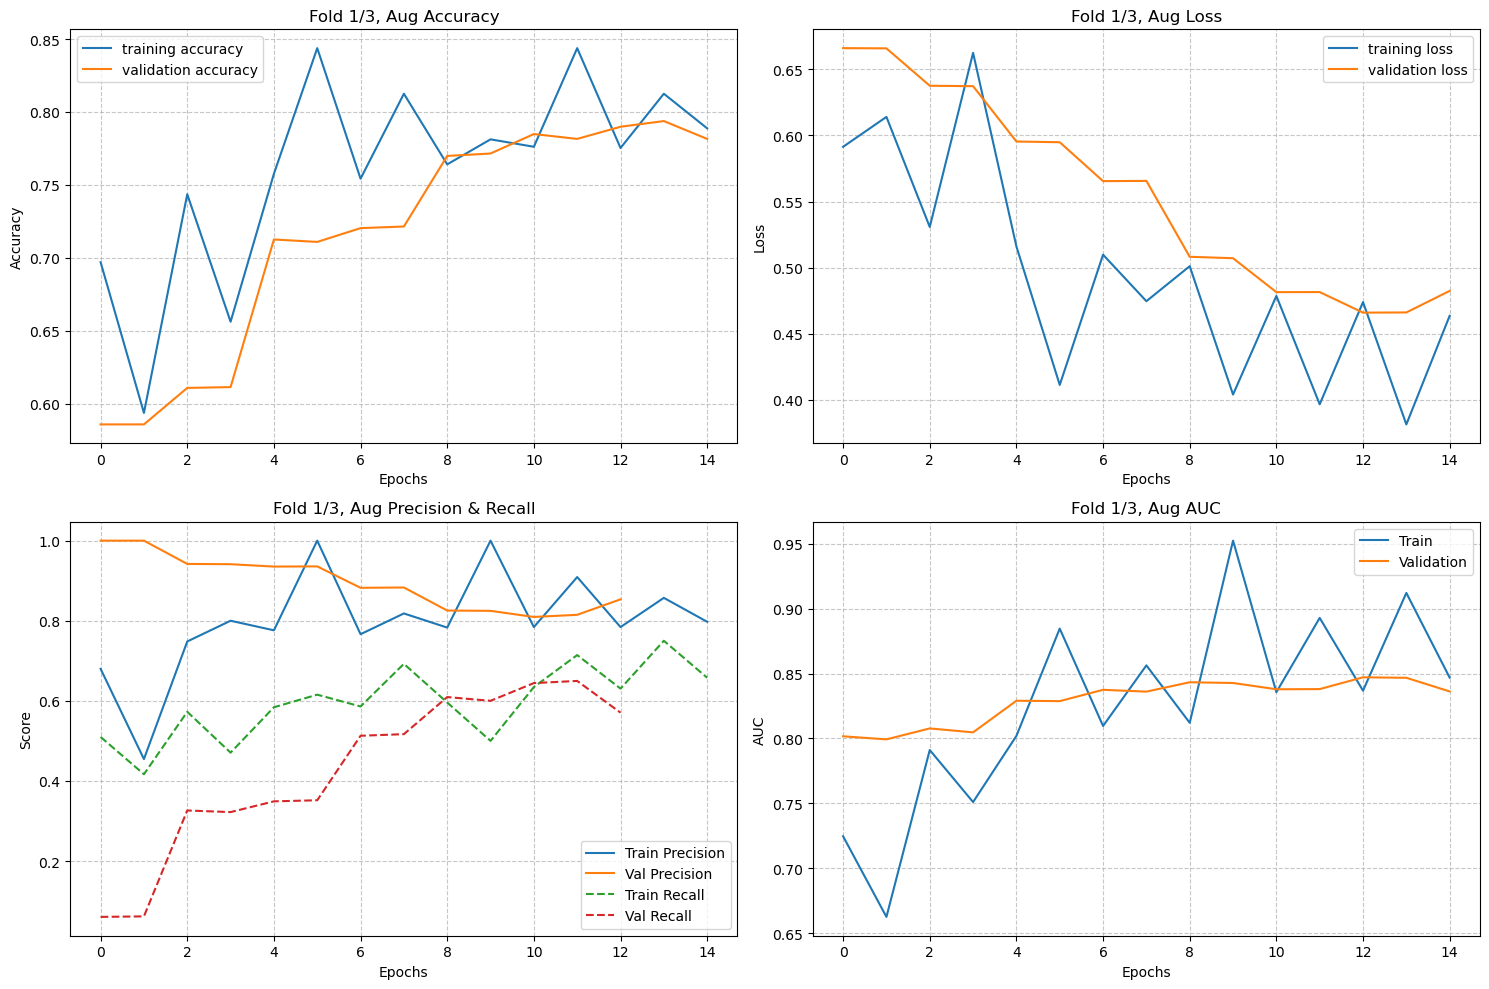

57/57 ━━━━━━━━━━━━━━━━━━━━ 37s 639ms/step
Fold 1/3, Aug Model Evaluation:
Accuracy: 0.7899
Precision: 0.8094
Recall: 0.6443
F1 Score: 0.7175
Kappa Score: 0.5536

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.89      0.83      1054
           1       0.81      0.64      0.72       745

    accuracy                           0.79      1799
   macro avg       0.79      0.77      0.78      1799
weighted avg       0.79      0.79      0.79      1799



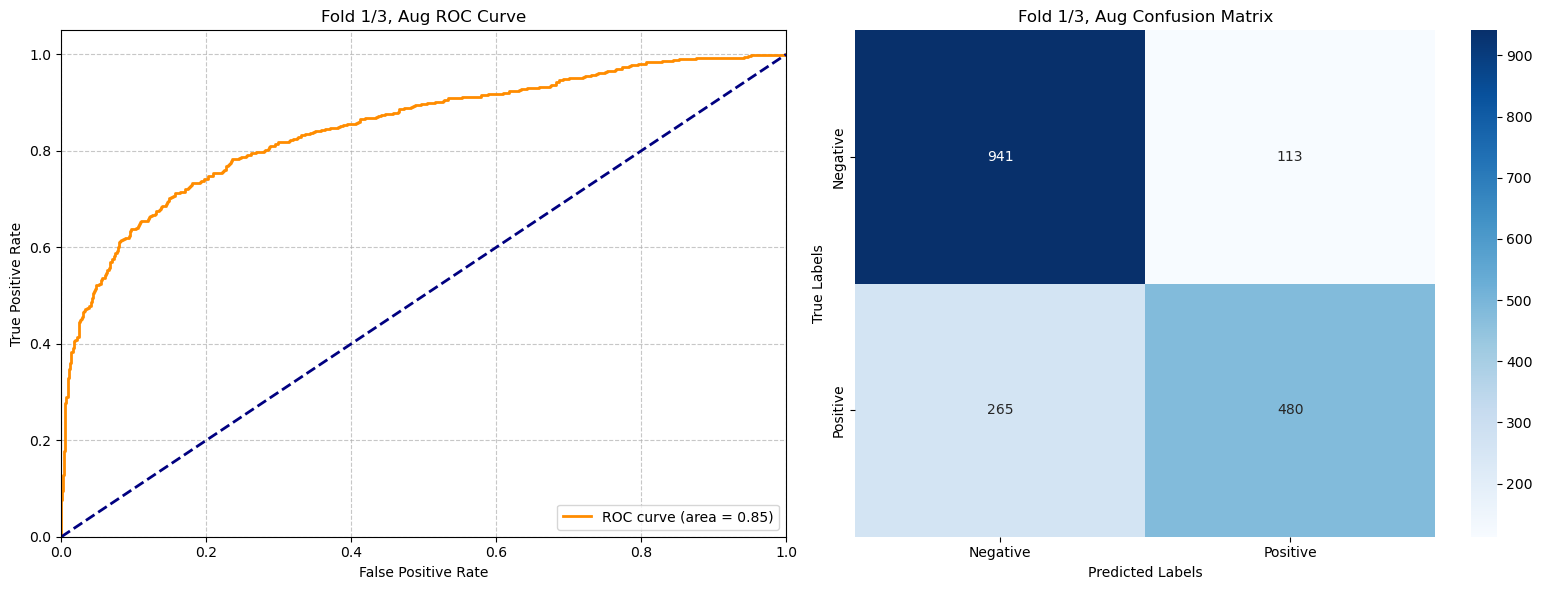

Model saved to ./saved_models/bone_fracture_cv_fold_1_of_3_aug.h5

Training fold 2/3...
Training samples: 3597, Test samples: 1799


/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 655ms/step - AUC: 0.6821 - Precision: 0.5961 - Recall: 0.5160 - accuracy: 0.6451 - loss: 0.6315
Epoch 1: val_accuracy improved from -inf to 0.58533, saving model to ./saved_models/cv_fold_2_of_3_aug_20250508-152158.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step - AUC: 0.6825 - Precision: 0.5966 - Recall: 0.5161 - accuracy: 0.6455 - loss: 0.6312 - val_AUC: 0.7885 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5853 - val_loss: 0.6654 - learning_rate: 0.0010
Epoch 2/15
  1/112 ━━━━━━━━━━━━━━━━━━━━ 1:14 670ms/step - AUC: 0.7020 - Precision: 0.6667 - Recall: 0.4000 - accuracy: 0.6250 - loss: 0.6604

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy did not improve from 0.58533
112/112 ━━━━━━━━━━━━━━━━━━━━ 38s 335ms/step - AUC: 0.7020 - Precision: 0.6667 - Recall: 0.4000 - accuracy: 0.6250 - loss: 0.6604 - val_AUC: 0.7906 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5853 - val_loss: 0.6654 - learning_rate: 0.0010
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 657ms/step - AUC: 0.7930 - Precision: 0.7733 - Recall: 0.5500 - accuracy: 0.7557 - loss: 0.5162
Epoch 3: val_accuracy improved from 0.58533 to 0.64981, saving model to ./saved_models/cv_fold_2_of_3_aug_20250508-152158.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 112s 998ms/step - AUC: 0.7929 - Precision: 0.7733 - Recall: 0.5501 - accuracy: 0.7557 - loss: 0.5163 - val_AUC: 0.8041 - val_Precision: 0.9462 - val_Recall: 0.1649 - val_accuracy: 0.6498 - val_loss: 0.6413 - learning_rate: 0.0010
Epoch 4/15
  1/112 ━━━━━━━━━━━━━━━━━━━━ 1:13 662ms/step - AUC: 0.9000 - Precision: 1.0000 - Recall: 0.4091 - accuracy: 0.5938 - loss: 0.6358
Epoch 4: val_ac

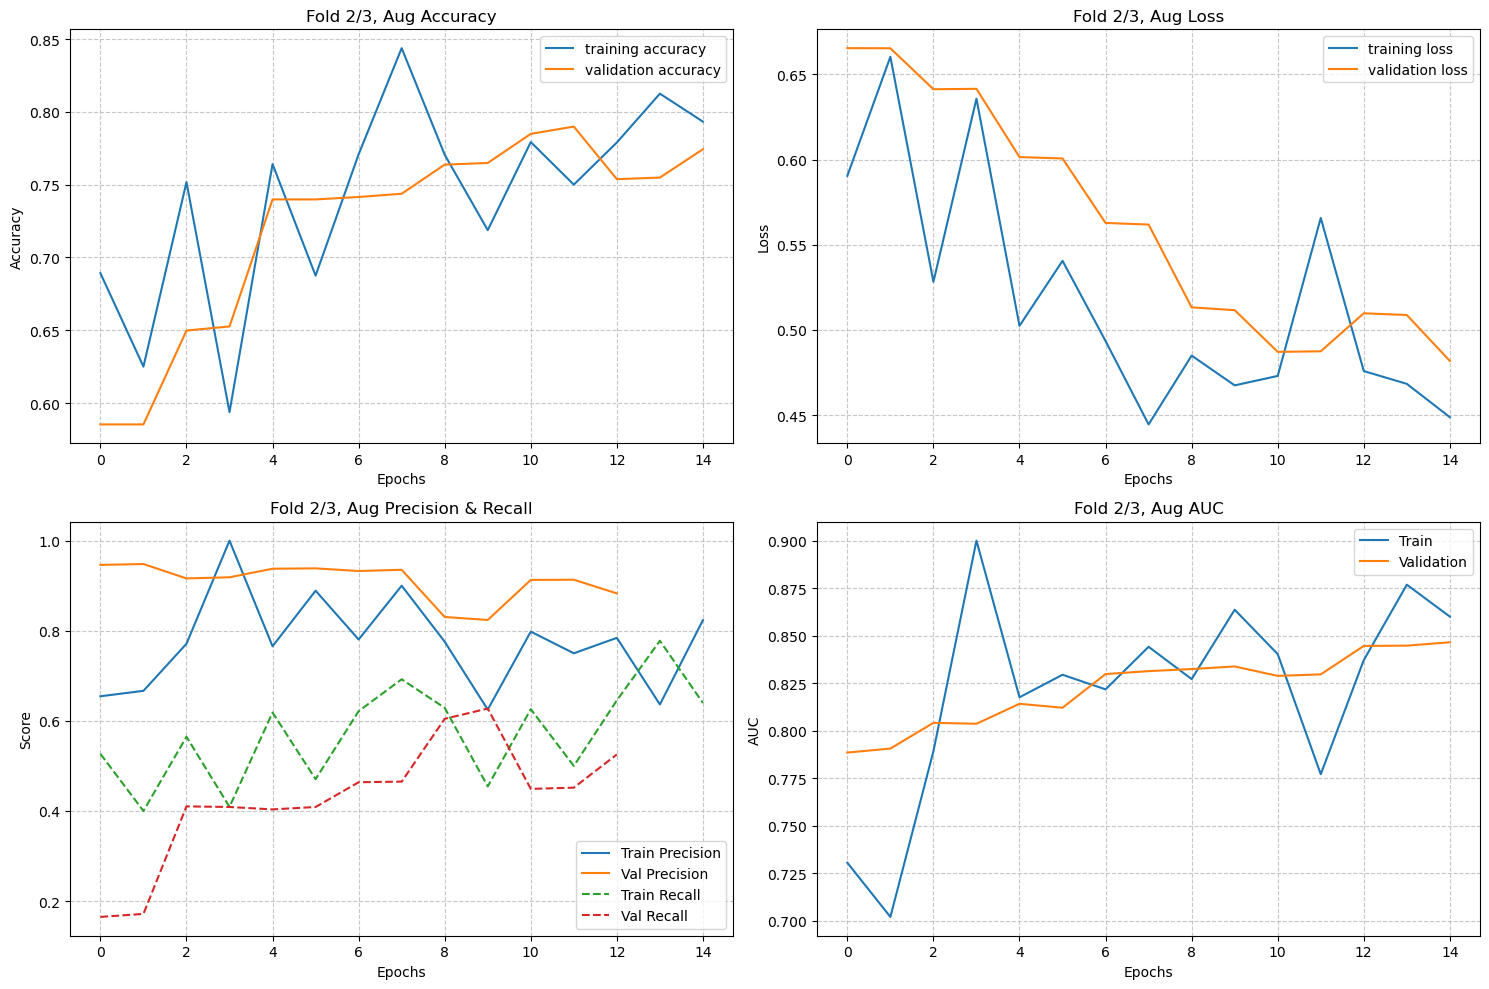

57/57 ━━━━━━━━━━━━━━━━━━━━ 41s 702ms/step
Fold 2/3, Aug Model Evaluation:
Accuracy: 0.7743
Precision: 0.8829
Recall: 0.5255
F1 Score: 0.6588
Kappa Score: 0.5059

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.95      0.83      1053
           1       0.88      0.53      0.66       746

    accuracy                           0.77      1799
   macro avg       0.81      0.74      0.75      1799
weighted avg       0.80      0.77      0.76      1799



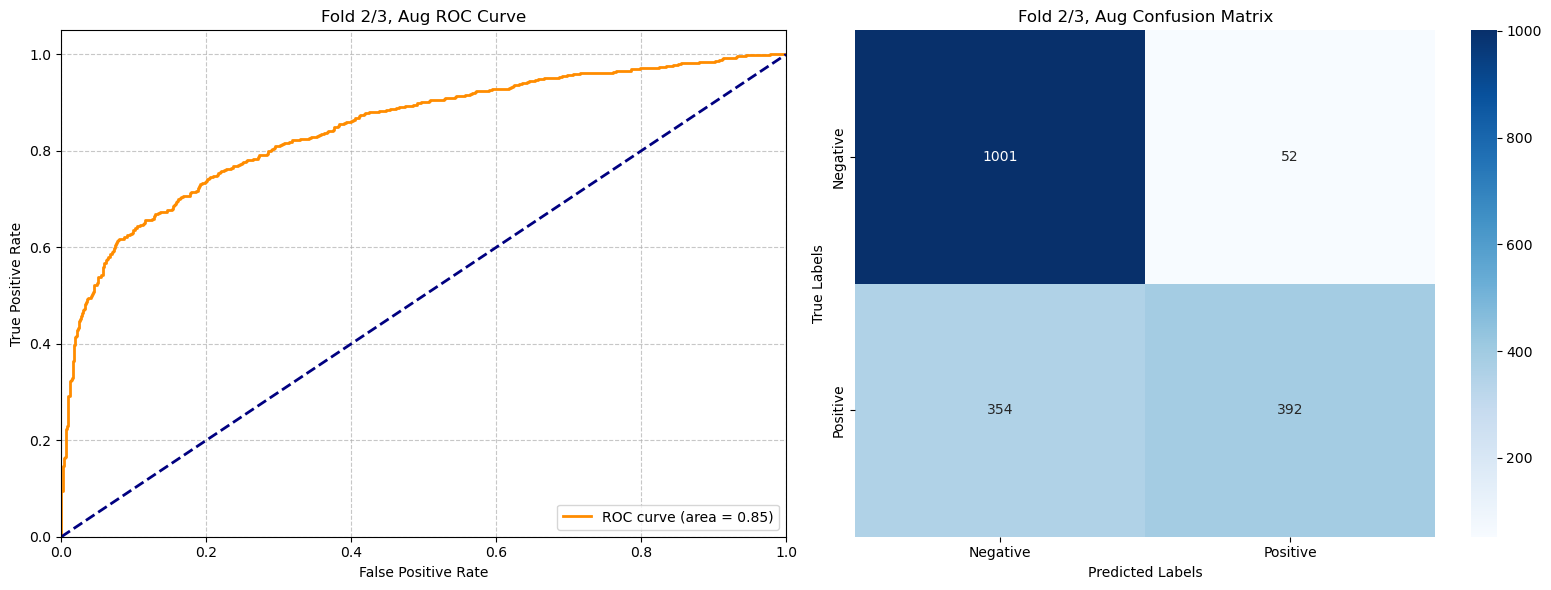

Model saved to ./saved_models/bone_fracture_cv_fold_2_of_3_aug.h5

Training fold 3/3...
Training samples: 3598, Test samples: 1798


/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 847ms/step - AUC: 0.6831 - Precision: 0.5910 - Recall: 0.5153 - accuracy: 0.6517 - loss: 0.6221Error in fold 3: {{function_node __wrapped__CreateSummaryFileWriter_device_/job:localhost/replica:0/task:0/device:CPU:0}} ./logs/cv_fold_3_of_3_aug_20250508-154232/validation; No space left on device [Op:CreateSummaryFileWriter] name: 

----------------------------------------
 Average metrics for 3-fold cross validation:
----------------------------------------
Accuracy: 0.7821
Precision: 0.8462
Recall: 0.5849
F1 Score: 0.6882
Kappa Score: 0.5298
ROC AUC: 0.8469


2025-05-08 15:44:17.441605: W tensorflow/core/framework/op_kernel.cc:1839] OP_REQUIRES failed at summary_kernels.cc:65 : RESOURCE_EXHAUSTED: ./logs/cv_fold_3_of_3_aug_20250508-154232/validation; No space left on device
2025-05-08 15:44:17.441626: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: RESOURCE_EXHAUSTED: ./logs/cv_fold_3_of_3_aug_20250508-154232/validation; No space left on device


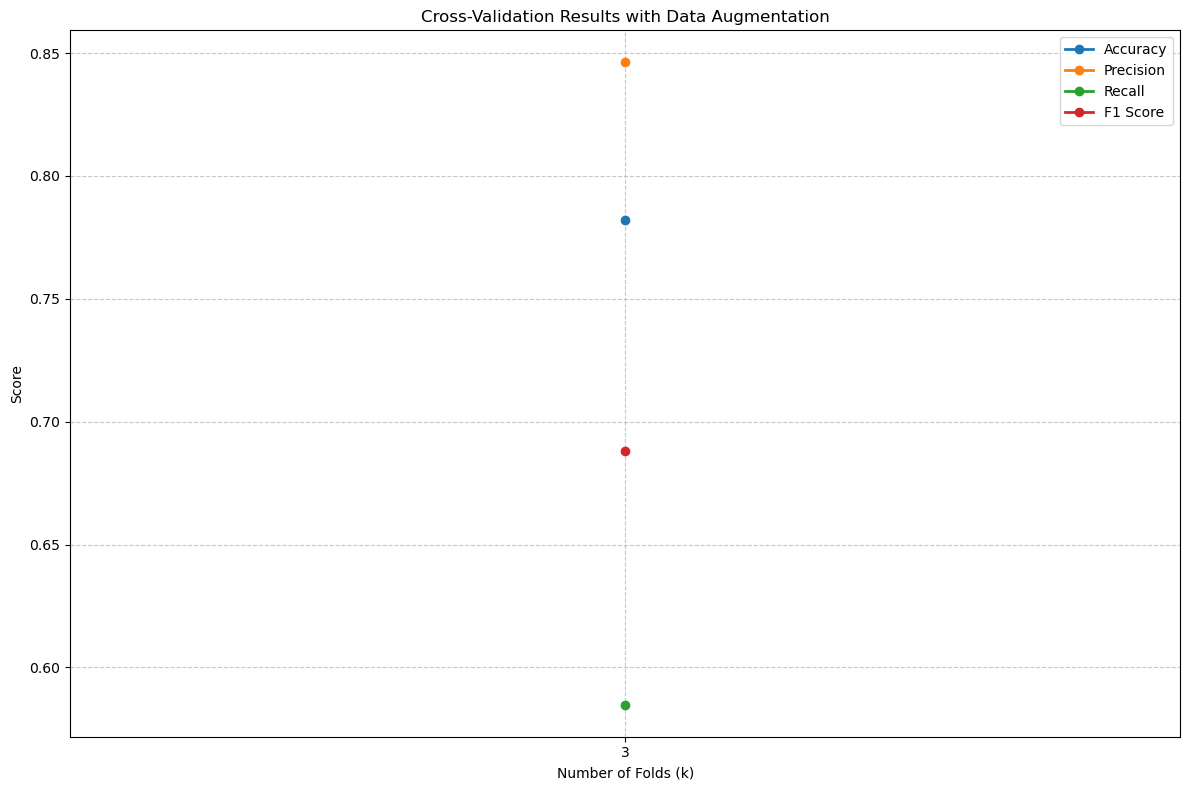

In [ ]:
# 2. Cross-validation with different k values
# With augmentation
cv_results_aug = k_fold_cross_validation(k_values=[3], epochs=15, use_augmentation=True)

In [ ]:
# Functions for dataset distribution analysis

def plot_class_distribution(labels, title="Class Distribution"):
    """
    Plot the distribution of classes in the dataset using different visualizations.

    Args:
        labels: Array of labels (0 for fractured, 1 for not fractured)
        title: Title for the plot
    """
    # Count classes
    fractured_count = np.sum(labels == 0)
    not_fractured_count = np.sum(labels == 1)

    class_names = ['Fractured', 'Not Fractured']
    class_counts = [fractured_count, not_fractured_count]

    # Create a figure with multiple plots
    fig = plt.figure(figsize=(18, 6))

    # 1. Bar chart
    plt.subplot(1, 3, 1)
    sns.barplot(x=class_names, y=class_counts)
    plt.title(f"{title} - Bar Chart")
    plt.ylabel("Number of Images")
    plt.grid(True, linestyle='--', alpha=0.7)

    # Calculate percentages
    total = fractured_count + not_fractured_count
    percentages = [count/total*100 for count in class_counts]

    # 2. Pie chart
    plt.subplot(1, 3, 2)
    plt.pie(class_counts, labels=class_names, autopct='%1.1f%%',
            startangle=90, shadow=True, explode=(0.05, 0))
    plt.axis('equal')
    plt.title(f"{title} - Pie Chart")

    # 3. Horizontal bar chart with percentages
    plt.subplot(1, 3, 3)
    ax = sns.barplot(y=class_names, x=class_counts, orient='h', palette='viridis')

    # Add percentage annotations
    for i, p in enumerate(percentages):
        ax.text(class_counts[i] + total*0.01, i, f'{p:.1f}%', va='center')

    plt.title(f"{title} - Horizontal Bar Chart")
    plt.xlabel("Number of Images")
    plt.tight_layout()
    plt.show()

    # Print summary
    print(f"Class distribution:")
    print(f"- Fractured: {fractured_count} images ({percentages[0]:.1f}%)")
    print(f"- Not Fractured: {not_fractured_count} images ({percentages[1]:.1f}%)")

    # Check for class imbalance
    imbalance_ratio = max(percentages) / min(percentages)
    print(f"Class imbalance ratio: {imbalance_ratio:.2f}")
    if imbalance_ratio > 1.5:
        print("Note: There appears to be class imbalance in the dataset.")


def analyze_image_features(data, labels, sample_size=1000):
    """
    Analyze and visualize the distribution of image features.

    Args:
        data: Array of images
        labels: Array of labels
        sample_size: Number of images to sample for analysis
    """
    # Sample images if dataset is large
    if len(data) > sample_size:
        indices = np.random.choice(range(len(data)), sample_size, replace=False)
        sampled_data = data[indices]
        sampled_labels = labels[indices]
    else:
        sampled_data = data
        sampled_labels = labels

    # Create arrays for each class
    fractured_images = sampled_data[sampled_labels == 0]
    not_fractured_images = sampled_data[sampled_labels == 1]

    # Calculate image statistics
    def get_image_stats(images):
        # Mean brightness per image
        brightness = np.mean(images, axis=(1, 2, 3))

        # Contrast (standard deviation of pixel values)
        contrast = np.std(images, axis=(1, 2, 3))

        # RGB channel averages
        r_channel = np.mean(images[:, :, :, 0], axis=(1, 2))
        g_channel = np.mean(images[:, :, :, 1], axis=(1, 2))
        b_channel = np.mean(images[:, :, :, 2], axis=(1, 2))

        return brightness, contrast, r_channel, g_channel, b_channel

    # Get stats for each class
    f_brightness, f_contrast, f_r, f_g, f_b = get_image_stats(fractured_images)
    nf_brightness, nf_contrast, nf_r, nf_g, nf_b = get_image_stats(not_fractured_images)

    # Create visualizations
    plt.figure(figsize=(20, 15))

    # 1. Brightness distribution
    plt.subplot(3, 2, 1)
    sns.histplot(f_brightness, label='Fractured', kde=True, color='red', alpha=0.5)
    sns.histplot(nf_brightness, label='Not Fractured', kde=True, color='blue', alpha=0.5)
    plt.title('Brightness Distribution')
    plt.xlabel('Mean Pixel Value')
    plt.legend()

    # 2. Contrast distribution
    plt.subplot(3, 2, 2)
    sns.histplot(f_contrast, label='Fractured', kde=True, color='red', alpha=0.5)
    sns.histplot(nf_contrast, label='Not Fractured', kde=True, color='blue', alpha=0.5)
    plt.title('Contrast Distribution')
    plt.xlabel('Standard Deviation of Pixel Values')
    plt.legend()

    # 3. RGB Channel comparison - Violin plot
    plt.subplot(3, 2, 3)

    # Prepare data for violin plot
    channel_data = []

    for values, channel, class_name in [
        (f_r, 'R', 'Fractured'),
        (f_g, 'G', 'Fractured'),
        (f_b, 'B', 'Fractured'),
        (nf_r, 'R', 'Not Fractured'),
        (nf_g, 'G', 'Not Fractured'),
        (nf_b, 'B', 'Not Fractured')
    ]:
        for value in values:
            channel_data.append({
                'Channel': channel,
                'Value': value,
                'Class': class_name
            })

    channel_df = pd.DataFrame(channel_data)
    sns.violinplot(x='Channel', y='Value', hue='Class', data=channel_df, split=True, inner='quart')
    plt.title('RGB Channel Distribution (Violin Plot)')
    plt.grid(True, linestyle='--', alpha=0.3)

    # 4. RGB Channel comparison - Box plot
    plt.subplot(3, 2, 4)
    sns.boxplot(x='Channel', y='Value', hue='Class', data=channel_df)
    plt.title('RGB Channel Distribution (Box Plot)')
    plt.grid(True, linestyle='--', alpha=0.3)

    # 5. Skewness analysis
    plt.subplot(3, 2, 5)

    # Calculate skewness
    from scipy.stats import skew

    metrics = {
        'Brightness': [skew(f_brightness), skew(nf_brightness)],
        'Contrast': [skew(f_contrast), skew(nf_contrast)],
        'R Channel': [skew(f_r), skew(nf_r)],
        'G Channel': [skew(f_g), skew(nf_g)],
        'B Channel': [skew(f_b), skew(nf_b)]
    }

    # Create a DataFrame for visualization
    skew_data = []
    for metric, values in metrics.items():
        skew_data.append({'Metric': metric, 'Skewness': values[0], 'Class': 'Fractured'})
        skew_data.append({'Metric': metric, 'Skewness': values[1], 'Class': 'Not Fractured'})

    skew_df = pd.DataFrame(skew_data)

    # Plot skewness
    sns.barplot(x='Metric', y='Skewness', hue='Class', data=skew_df)
    plt.title('Feature Skewness Analysis')
    plt.xticks(rotation=45)
    plt.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    plt.grid(True, linestyle='--', alpha=0.3)

    # 6. Pixel intensity histograms
    plt.subplot(3, 2, 6)

    # Calculate histogram for a sample of images
    f_sample = fractured_images[:min(50, len(fractured_images))].reshape(-1)
    nf_sample = not_fractured_images[:min(50, len(not_fractured_images))].reshape(-1)

    sns.histplot(f_sample, label='Fractured', kde=True, color='red', alpha=0.3, bins=50, stat='density')
    sns.histplot(nf_sample, label='Not Fractured', kde=True, color='blue', alpha=0.3, bins=50, stat='density')
    plt.title('Pixel Intensity Distribution')
    plt.xlabel('Pixel Value')
    plt.legend()

    plt.tight_layout()
    plt.show()


def pixel_intensity_distribution_by_color_channel(data, labels, n_samples=5):
    """
    Plot pixel intensity distribution by color channel for a few sample images.

    Args:
        data: Array of images
        labels: Array of labels
        n_samples: Number of sample images to show
    """
    # Randomly select samples from each class
    fractured_indices = np.where(labels == 0)[0]
    not_fractured_indices = np.where(labels == 1)[0]

    f_samples = np.random.choice(fractured_indices, min(n_samples, len(fractured_indices)), replace=False)
    nf_samples = np.random.choice(not_fractured_indices, min(n_samples, len(not_fractured_indices)), replace=False)

    # Create figure
    plt.figure(figsize=(20, n_samples * 5))

    for i, (idx, class_name) in enumerate([(idx, 'Fractured') for idx in f_samples] +
                                          [(idx, 'Not Fractured') for idx in nf_samples]):
        # Get image
        img = data[idx]

        # Plot original image
        plt.subplot(n_samples * 2, 4, i * 4 + 1)
        plt.imshow(img)
        plt.title(f"{class_name} - Original")
        plt.axis('off')

        # Plot RGB histograms
        channels = ['Red', 'Green', 'Blue']
        colors = ['red', 'green', 'blue']

        for j, (channel, color) in enumerate(zip(range(3), colors)):
            plt.subplot(n_samples * 2, 4, i * 4 + j + 2)
            sns.histplot(img[:, :, channel].flatten(), color=color, kde=True, bins=50)
            plt.title(f"{channels[j]} Channel")
            plt.xlabel("Pixel Value")
            plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [ ]:
def visualize_metrics_with_different_graphs(results_df):
    """
    Visualize model metrics using different graph types.

    Args:
        results_df: DataFrame containing model results
    """
    # Create a copy and select top experiments
    top_results = results_df.head(8).copy()

    # 1. Radar chart for metrics comparison
    plt.figure(figsize=(22, 18))

    # First plot - Radar chart
    plt.subplot(2, 2, 1)

    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']
    N = len(metrics)

    # Create angles for each metric
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]  # Close the circle

    # Initialize figure
    ax = plt.subplot(2, 2, 1, polar=True)

    # Draw experiments
    for i, row in top_results.iterrows():
        values = [row[metric] for metric in metrics]
        values += values[:1]  # Close the circle

        # Plot values
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=row['Experiment'])
        ax.fill(angles, values, alpha=0.1)

    # Set labels
    plt.xticks(angles[:-1], metrics)
    ax.set_rlabel_position(0)
    plt.yticks([0.7, 0.8, 0.9, 1.0], ["0.7", "0.8", "0.9", "1.0"], color="grey", size=8)
    plt.ylim(0.7, 1.0)

    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.title("Model Performance Metrics - Radar Chart", size=15)

    # 2. Heatmap for all metrics
    plt.subplot(2, 2, 2)

    # Prepare data for heatmap
    heatmap_data = top_results.set_index('Experiment')[metrics].T

    # Plot heatmap
    sns.heatmap(heatmap_data, annot=True, cmap="YlGnBu", vmin=0.7, vmax=1.0,
                linewidths=.5, cbar_kws={'label': 'Score'})
    plt.title("Performance Metrics Heatmap")
    plt.tight_layout()

    # 3. Parallel coordinates plot
    plt.subplot(2, 2, 3)

    # Create a DataFrame for parallel coordinates
    parallel_data = top_results[metrics].copy()

    # Add experiment column for coloring
    parallel_data['Experiment'] = top_results['Experiment']

    # Create the parallel coordinates plot
    pd.plotting.parallel_coordinates(parallel_data, 'Experiment', colormap=plt.cm.Set2)
    plt.ylim(0.7, 1.0)
    plt.xticks(rotation=15)
    plt.title("Parallel Coordinates Plot of Metrics")
    plt.grid(True, linestyle='--', alpha=0.3)

    # 4. Stacked bar chart
    plt.subplot(2, 2, 4)

    # Define metrics to display in the stacked chart
    metrics_to_stack = ['Precision', 'Recall', 'F1 Score']

    # Data for stacked bar chart
    stacked_data = top_results[['Experiment'] + metrics_to_stack].melt(
        id_vars='Experiment',
        value_vars=metrics_to_stack,
        var_name='Metric',
        value_name='Value'
    )

    # Create a stacked bar chart
    sns.barplot(x='Experiment', y='Value', hue='Metric', data=stacked_data)
    plt.xticks(rotation=90)
    plt.title("Precision, Recall and F1 Comparison")
    plt.ylim(0.7, 1.0)
    plt.tight_layout()

    plt.show()


def visualize_cross_validation_with_different_graphs(cv_results, use_augmentation):
    """
    Visualize cross-validation results with different graph types.

    Args:
        cv_results: Dictionary containing cross-validation results
        use_augmentation: Boolean indicating if data augmentation was used
    """
    # Prepare data
    k_values = []
    metrics_by_fold = []

    for k, result in cv_results.items():
        for fold_idx, fold_metric in enumerate(result['fold_metrics']):
            metrics_by_fold.append({
                'k': k,
                'Fold': fold_idx + 1,
                'Accuracy': fold_metric['accuracy'],
                'Precision': fold_metric['precision'],
                'Recall': fold_metric['recall'],
                'F1 Score': fold_metric['f1'],
                'ROC AUC': fold_metric['roc_auc']
            })
        k_values.append(k)

    # Convert to DataFrame
    cv_df = pd.DataFrame(metrics_by_fold)

    # Create multiple visualizations
    plt.figure(figsize=(20, 15))

    # 1. Violin plot for accuracy distribution
    plt.subplot(2, 2, 1)
    sns.violinplot(x='k', y='Accuracy', data=cv_df)
    plt.title(f'Accuracy Distribution Across Folds {"with" if use_augmentation else "without"} Augmentation')
    plt.xlabel('Number of Folds (k)')
    plt.ylabel('Accuracy')
    plt.grid(True, linestyle='--', alpha=0.3)

    # 2. Boxplots for all metrics
    plt.subplot(2, 2, 2)

    # Melt the DataFrame to get all metrics in one column
    melted_df = cv_df.melt(
        id_vars=['k', 'Fold'],
        value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC'],
        var_name='Metric',
        value_name='Score'
    )

    sns.boxplot(x='Metric', y='Score', hue='k', data=melted_df)
    plt.title(f'Performance Metrics Distribution {"with" if use_augmentation else "without"} Augmentation')
    plt.ylim(0.7, 1.0)
    plt.grid(True, linestyle='--', alpha=0.3)

    # 3. Swarm plot for individual fold results
    plt.subplot(2, 2, 3)
    sns.swarmplot(x='k', y='F1 Score', hue='Fold', data=cv_df)
    plt.title(f'F1 Score by Individual Folds {"with" if use_augmentation else "without"} Augmentation')
    plt.xlabel('Number of Folds (k)')
    plt.ylabel('F1 Score')
    plt.ylim(0.7, 1.0)
    plt.grid(True, linestyle='--', alpha=0.3)

    # 4. Line plot with error bars
    plt.subplot(2, 2, 4)

    # Calculate mean and std for each metric and k value
    summary = cv_df.groupby('k').agg(['mean', 'std'])

    # Extract mean and std for plotting
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

    for metric in metrics:
        means = [summary[(metric, 'mean')][k] for k in k_values]
        stds = [summary[(metric, 'std')][k] for k in k_values]

        plt.errorbar(k_values, means, yerr=stds, fmt='-o', capsize=5, label=metric)

    plt.title(f'Mean Performance with Error Bars {"with" if use_augmentation else "without"} Augmentation')
    plt.xlabel('Number of Folds (k)')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.ylim(0.7, 1.0)

    plt.tight_layout()
    plt.show()


def plot_skewness_analysis(results_df):
    """
    Analyze and visualize skewness in model performance.

    Args:
        results_df: DataFrame containing model results
    """
    plt.figure(figsize=(15, 10))

    # 1. Distribution of metrics
    plt.subplot(2, 2, 1)

    # Melt the DataFrame to get all metrics in one column
    melted_df = results_df.melt(
        id_vars=['Experiment', 'Type'],
        value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC'],
        var_name='Metric',
        value_name='Score'
    )

    # Plot density plots for each metric
    for metric in ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']:
        sns.kdeplot(melted_df[melted_df['Metric'] == metric]['Score'], label=metric)

    plt.title('Distribution of Performance Metrics')
    plt.xlabel('Score')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.3)

    # 2. Skewness of each metric
    plt.subplot(2, 2, 2)

    # Calculate skewness for each metric
    from scipy.stats import skew

    metric_skewness = []
    for metric in ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']:
        metric_skewness.append({
            'Metric': metric,
            'Skewness': skew(results_df[metric])
        })

    skew_df = pd.DataFrame(metric_skewness)

    # Create barplot
    sns.barplot(x='Metric', y='Skewness', data=skew_df)
    plt.title('Skewness of Performance Metrics')
    plt.axhline(y=0, color='black', linestyle='-', alpha=0.5)
    plt.grid(True, linestyle='--', alpha=0.3)

    # 3. Performance by experiment type
    plt.subplot(2, 2, 3)

    # Compare metrics by experiment type
    sns.boxplot(x='Type', y='Score', hue='Metric', data=melted_df)
    plt.title('Metrics by Experiment Type')
    plt.ylim(0.7, 1.0)
    plt.grid(True, linestyle='--', alpha=0.3)

    # 4. Precision-Recall relationship
    plt.subplot(2, 2, 4)

    # Scatter plot of precision vs recall
    sns.scatterplot(x='Precision', y='Recall', hue='Type',
                  size='F1 Score', sizes=(50, 250),
                  data=results_df)

    plt.title('Precision-Recall Relationship')
    plt.xlim(0.7, 1.0)
    plt.ylim(0.7, 1.0)
    plt.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()


=== Analyzing Dataset Distribution ===


/var/folders/_4/fmgmrqnx2xs4ysyvp3p3k46c0000gn/T/ipykernel_60058/1742639120.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y=class_names, x=class_counts, orient='h', palette='viridis')


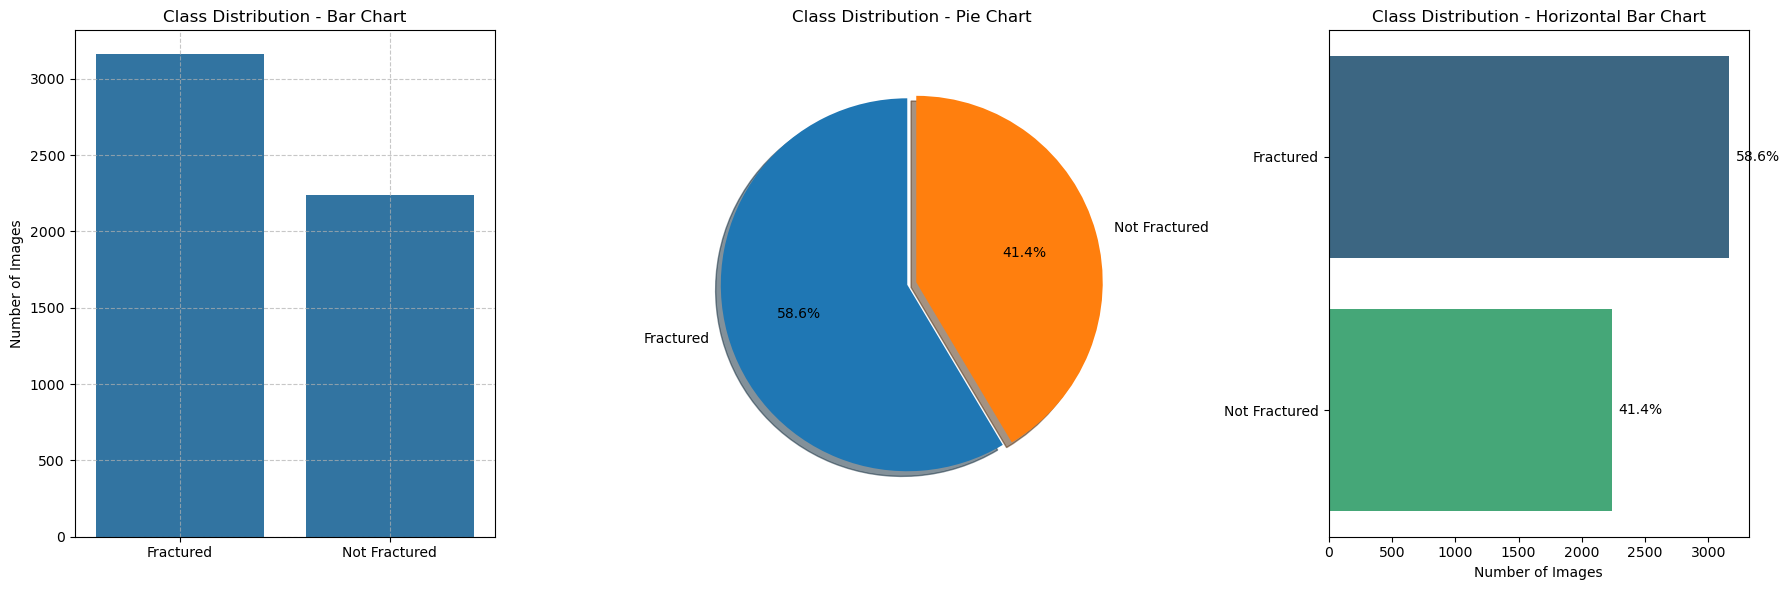

Class distribution:
- Fractured: 3160 images (58.6%)
- Not Fractured: 2236 images (41.4%)
Class imbalance ratio: 1.41


In [ ]:
# Analyze data distribution before training
print("\n=== Analyzing Dataset Distribution ===")
plot_class_distribution(labels)



=== Analyzing Image Features ===


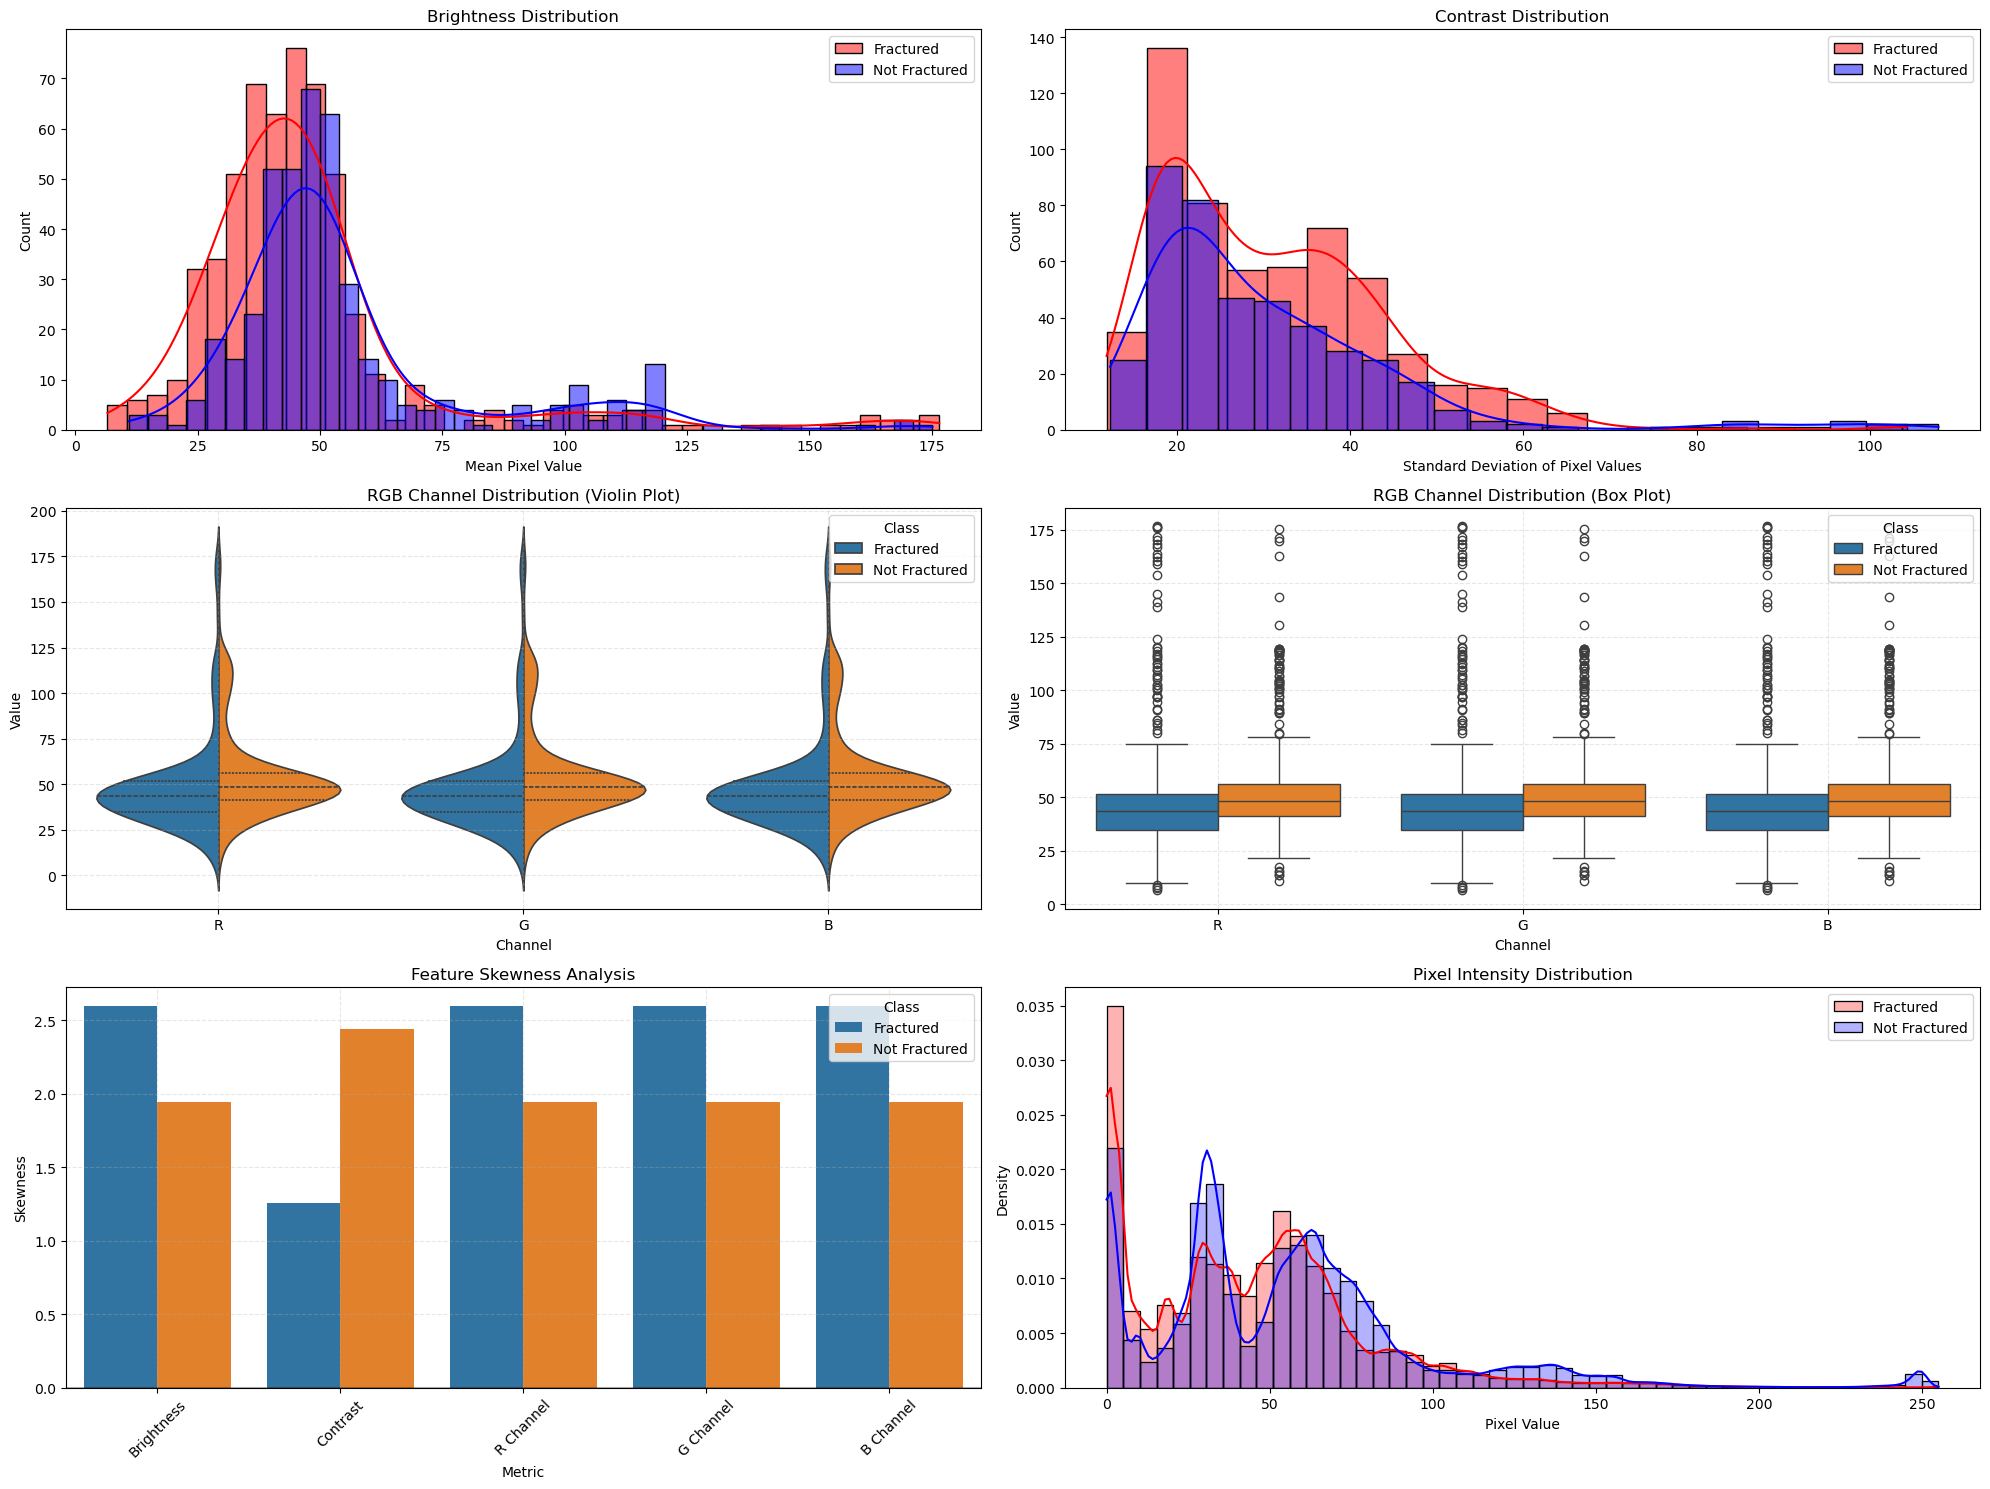

In [ ]:

# Analyze image features
print("\n=== Analyzing Image Features ===")
analyze_image_features(data, labels)




=== Analyzing Pixel Intensity Distribution by Color Channel ===


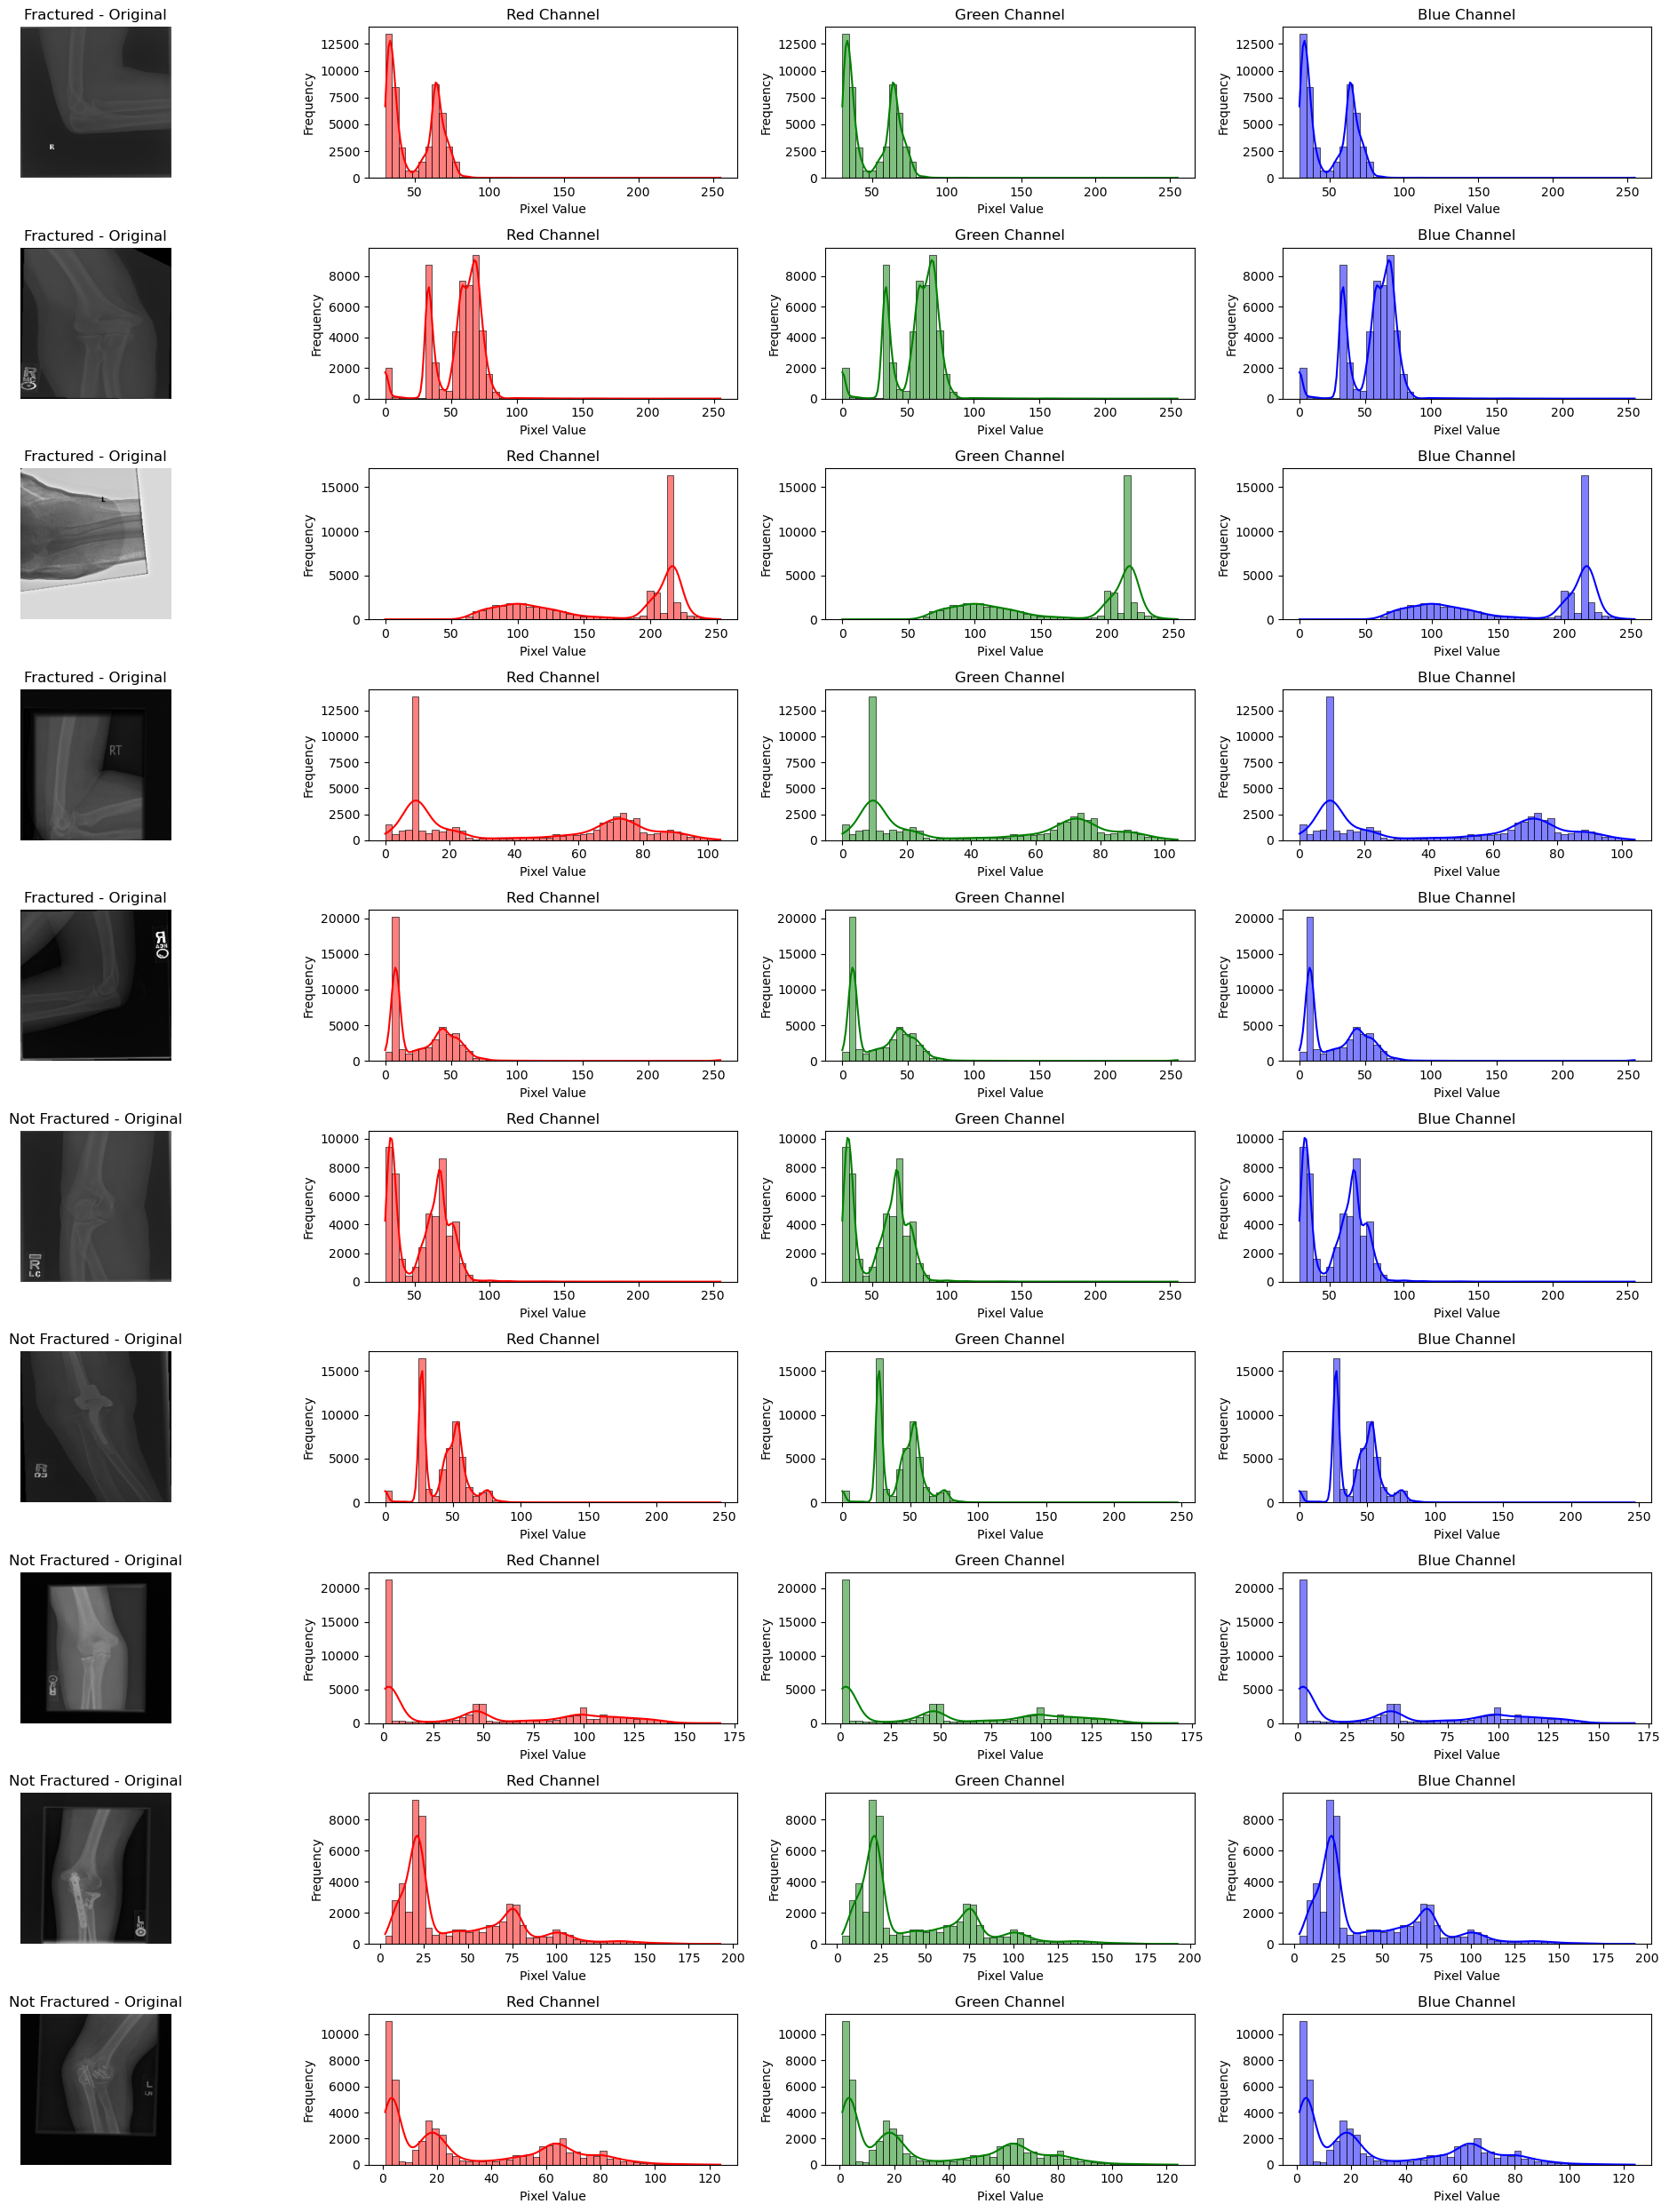

In [ ]:
# Show pixel intensity distribution by color channel
print("\n=== Analyzing Pixel Intensity Distribution by Color Channel ===")
pixel_intensity_distribution_by_color_channel(data, labels)

